<a href="https://colab.research.google.com/github/Samyuktha-77/Unsupervised/blob/main/PCA2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
# 1.import libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml
from sklearn.decomposition import PCA

In [17]:
# 2.Load MNIST dataset
mnist = fetch_openml("mnist_784", version=1, as_frame=False)
X=mnist.data



In [18]:
# 3. Use a subset to make executuion faster
#selects the first 5000 images to reduce execution time
X=X[:5000]
print("Original dataset shape: ", X.shape)

# 4. Normalize pixel values between 0 and 1
X=X/225.0

# 5. Apply PCA
pca=PCA(n_components=0.95)
X_reduced=pca.fit_transform(X)
print("Reduced dataset shape: ", X_reduced.shape)


Original dataset shape:  (5000, 784)
Reduced dataset shape:  (5000, 148)


Compressed dataset shape:  (5000, 148)


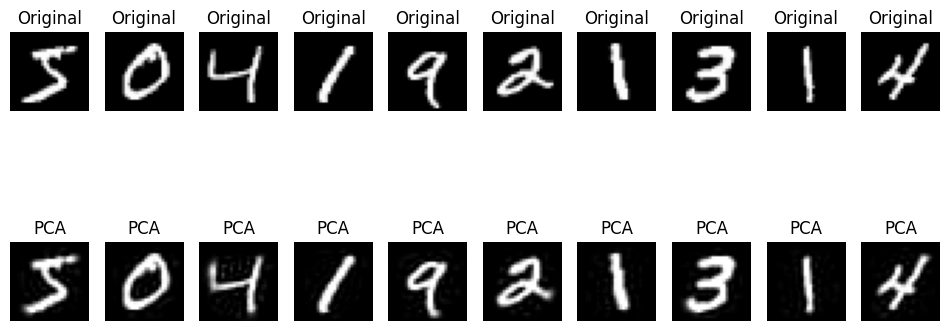

In [21]:
# 6. fit PCA and reduce dimensions
X_compressed = pca.fit_transform(X)
print("Compressed dataset shape: ", X_compressed.shape)

# 7. Reconstruct the images
X_reconstructed = pca.inverse_transform(X_compressed)

# 8. Display original and reconstructed images
plt.figure(figsize=(12, 5))
for i in range(10):
  plt.subplot(2, 10, i + 1)
  plt.imshow(X[i].reshape(28, 28), cmap="gray")
  plt.title("Original")
  plt.axis("off")
  plt.subplot(2, 10, i + 11)
  plt.imshow(X_reconstructed[i].reshape(28, 28), cmap="gray",
  vmin=0,
  vmax=1
  )
  plt.title("PCA")
  plt.axis("off")


In [25]:
print("Original dataset shape: ", X.shape)
print("Reduced dataset shape: ", pca.n_components_)
print("Explained variance:", round(sum(pca.explained_variance_ratio_),4))

reduction = (1- X_compressed.shape[1]/X.shape[1])*100
print("Dimensionality reduction: ", round(reduction, 2), "%")


Original dataset shape:  (5000, 784)
Reduced dataset shape:  148
Explained variance: 0.9501
Dimensionality reduction:  81.12 %
